In [5]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/praveenkottari/bd3-dataset-for-building-defect-detection/BD3_original_dataset/train/algae/cls00_414.jpg
/kaggle/input/datasets/praveenkottari/bd3-dataset-for-building-defect-detection/BD3_original_dataset/train/algae/cls00_444.jpg
/kaggle/input/datasets/praveenkottari/bd3-dataset-for-building-defect-detection/BD3_original_dataset/train/algae/cls00_571.jpg
/kaggle/input/datasets/praveenkottari/bd3-dataset-for-building-defect-detection/BD3_original_dataset/train/algae/cls00_145.jpg
/kaggle/input/datasets/praveenkottari/bd3-dataset-for-building-defect-detection/BD3_original_dataset/train/algae/cls00_249.jpg
/kaggle/input/datasets/praveenkottari/bd3-dataset-for-building-defect-detection/BD3_original_dataset/train/algae/cls00_618.jpg
/kaggle/input/datasets/praveenkottari/bd3-dataset-for-building-defect-detection/BD3_original_dataset/train/algae/cls00_344.jpg
/kaggle/input/datasets/praveenkottari/bd3-dataset-for-building-defect-detection/BD3_original_dataset/train/alga

In [6]:
import kagglehub

path = kagglehub.dataset_download(
    "praveenkottari/bd3-dataset-for-building-defect-detection"
)

print("Dataset downloaded to:", path)

Dataset downloaded to: /kaggle/input/datasets/praveenkottari/bd3-dataset-for-building-defect-detection


In [7]:
import os

for item in os.listdir(path):
    print(item)

BD3_original_dataset


In [8]:
dataset_dir = os.path.join(path, "BD3_original_dataset")

for item in os.listdir(dataset_dir):
    print(item)

train


In [9]:
train_dir = os.path.join(dataset_dir, "train")

for item in os.listdir(train_dir):
    print(item)

algae
major_crack
spalling
plain
minor_crack
stain
peeling


In [10]:
import os

for class_name in os.listdir(train_dir):
    class_path = os.path.join(train_dir, class_name)

    if os.path.isdir(class_path):
        count = len([
            f for f in os.listdir(class_path)
            if os.path.isfile(os.path.join(class_path, f))
        ])

        print(f"{class_name:15} {count}")

algae           620
major_crack     580
spalling        500
plain           600
minor_crack     624
stain           521
peeling         520


In [11]:
for item in os.listdir(dataset_dir):
    print(item)

train


In [12]:
from sklearn.model_selection import train_test_split
import os
import shutil

# Paths
source_dir = train_dir
split_dir = "/kaggle/working/bd3_split"

# Create folders
for split in ["train", "val", "test"]:
    for class_name in os.listdir(source_dir):
        class_path = os.path.join(source_dir, class_name)
        if os.path.isdir(class_path):
            os.makedirs(
                os.path.join(split_dir, split, class_name),
                exist_ok=True
            )

# Split each class separately
for class_name in os.listdir(source_dir):

    class_path = os.path.join(source_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    images = [
        f for f in os.listdir(class_path)
        if os.path.isfile(os.path.join(class_path, f))
    ]

    # 70% train, 30% temporary
    train_images, temp_images = train_test_split(
        images,
        test_size=0.30,
        random_state=42
    )

    # Split remaining 30% into 15% validation + 15% test
    val_images, test_images = train_test_split(
        temp_images,
        test_size=0.50,
        random_state=42
    )

    # Copy files
    for filename in train_images:
        shutil.copy2(
            os.path.join(class_path, filename),
            os.path.join(split_dir, "train", class_name, filename)
        )

    for filename in val_images:
        shutil.copy2(
            os.path.join(class_path, filename),
            os.path.join(split_dir, "val", class_name, filename)
        )

    for filename in test_images:
        shutil.copy2(
            os.path.join(class_path, filename),
            os.path.join(split_dir, "test", class_name, filename)
        )

print("Dataset split completed!")
print(split_dir)

Dataset split completed!
/kaggle/working/bd3_split


In [13]:
import os

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    split_path = os.path.join(split_dir, split)

    total = 0

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            count = len(os.listdir(class_path))
            total += count
            print(f"{class_name:15} {count}")

    print(f"Total: {total}")


TRAIN
algae           434
major_crack     406
minor_crack     436
peeling         364
plain           420
spalling        350
stain           364
Total: 2774

VAL
algae           93
major_crack     87
minor_crack     94
peeling         78
plain           90
spalling        75
stain           78
Total: 595

TEST
algae           93
major_crack     87
minor_crack     94
peeling         78
plain           90
spalling        75
stain           79
Total: 596


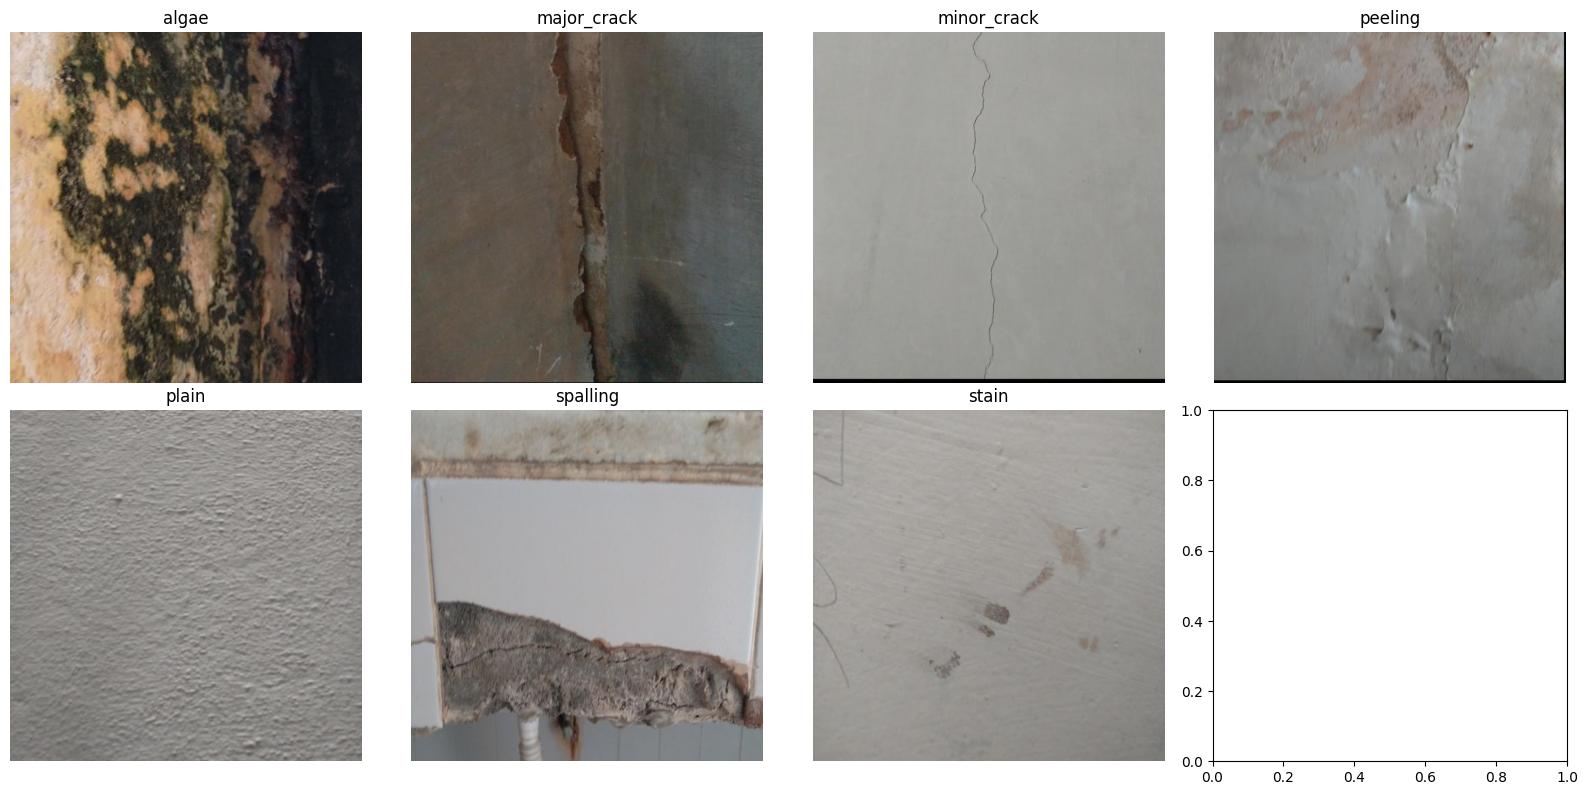

In [14]:
import matplotlib.pyplot as plt
from PIL import Image
import random
import os

classes = sorted(os.listdir(os.path.join(split_dir, "train")))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, class_name in zip(axes.flatten(), classes):
    class_path = os.path.join(split_dir, "train", class_name)

    image_name = random.choice(os.listdir(class_path))
    image_path = os.path.join(class_path, image_name)

    image = Image.open(image_path)

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.10.0+cu128
Torchvision: 0.25.0+cu128
GPU available: True
GPU: Tesla T4


In [16]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load datasets
train_dataset = datasets.ImageFolder(
    os.path.join(split_dir, "train"),
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    os.path.join(split_dir, "val"),
    transform=val_test_transform
)

test_dataset = datasets.ImageFolder(
    os.path.join(split_dir, "test"),
    transform=val_test_transform
)

# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

print("Classes:", train_dataset.classes)
print("Number of classes:", len(train_dataset.classes))
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Classes: ['algae', 'major_crack', 'minor_crack', 'peeling', 'plain', 'spalling', 'stain']
Number of classes: 7
Train batches: 87
Validation batches: 19
Test batches: 19


In [17]:
import torch
import torch.nn as nn
from torchvision import models

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained ResNet18
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Replace the final classification layer
num_features = model.fc.in_features

model.fc = nn.Linear(num_features, 7)

# Move model to GPU
model = model.to(device)

print(model.fc)
print("Device:", device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 230MB/s]


Linear(in_features=512, out_features=7, bias=True)
Device: cuda


In [18]:
import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("Loss:", criterion)
print("Optimizer:", optimizer)

Loss: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


In [19]:
num_epochs = 10

for epoch in range(num_epochs):

    # =====================
    # TRAINING
    # =====================
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    # =====================
    # VALIDATION
    # =====================
    model.eval()

    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

Epoch [1/10] Train Loss: 0.6523 | Train Acc: 77.18% | Val Loss: 0.3328 | Val Acc: 88.24%
Epoch [2/10] Train Loss: 0.2835 | Train Acc: 89.87% | Val Loss: 0.3293 | Val Acc: 88.40%
Epoch [3/10] Train Loss: 0.1906 | Train Acc: 93.08% | Val Loss: 0.2697 | Val Acc: 90.76%
Epoch [4/10] Train Loss: 0.1463 | Train Acc: 94.99% | Val Loss: 0.2833 | Val Acc: 90.42%
Epoch [5/10] Train Loss: 0.1191 | Train Acc: 95.93% | Val Loss: 0.3211 | Val Acc: 91.09%
Epoch [6/10] Train Loss: 0.0981 | Train Acc: 96.65% | Val Loss: 0.3212 | Val Acc: 90.08%
Epoch [7/10] Train Loss: 0.0869 | Train Acc: 97.30% | Val Loss: 0.3151 | Val Acc: 91.43%
Epoch [8/10] Train Loss: 0.0916 | Train Acc: 96.90% | Val Loss: 0.3175 | Val Acc: 90.42%
Epoch [9/10] Train Loss: 0.0821 | Train Acc: 97.26% | Val Loss: 0.3440 | Val Acc: 90.76%
Epoch [10/10] Train Loss: 0.0513 | Train Acc: 98.45% | Val Loss: 0.3954 | Val Acc: 90.08%


In [20]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 89.93%


In [21]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predictions = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

# Classification report
print(classification_report(
    all_labels,
    all_predictions,
    target_names=train_dataset.classes,
    digits=4
))

              precision    recall  f1-score   support

       algae     0.9381    0.9785    0.9579        93
 major_crack     0.8313    0.7931    0.8118        87
 minor_crack     0.8763    0.9043    0.8901        94
     peeling     0.8293    0.8718    0.8500        78
       plain     0.9677    1.0000    0.9836        90
    spalling     0.9155    0.8667    0.8904        75
       stain     0.9315    0.8608    0.8947        79

    accuracy                         0.8993       596
   macro avg     0.8985    0.8964    0.8969       596
weighted avg     0.8993    0.8993    0.8988       596



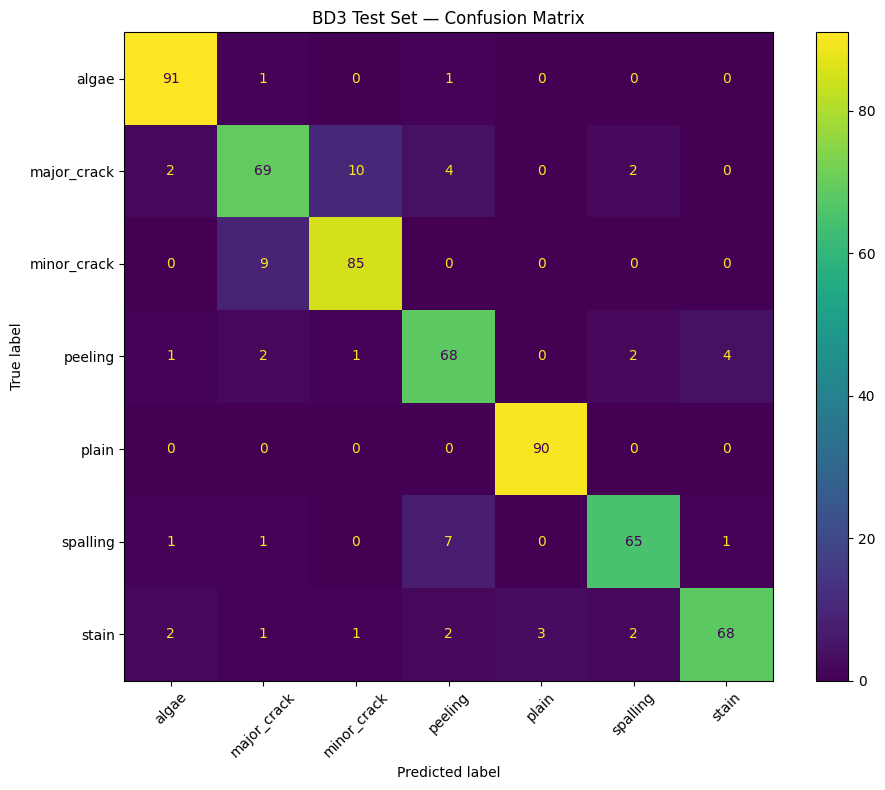

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    all_labels,
    all_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_dataset.classes
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d"
)

plt.title("BD3 Test Set — Confusion Matrix")
plt.tight_layout()
plt.show()

In [23]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Optimizer:", optimizer)
print("Scheduler:", scheduler)

Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)
Scheduler: <torch.optim.lr_scheduler.ReduceLROnPlateau object at 0x7e6f33e3b920>


In [24]:
num_epochs = 10

best_val_accuracy = 0.0

for epoch in range(num_epochs):

    # =====================
    # TRAINING
    # =====================
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    # =====================
    # VALIDATION
    # =====================
    model.eval()

    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = 100 * correct / total

    # Update learning rate
    scheduler.step(val_loss)

    # Save best model
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "/kaggle/working/best_resnet18.pth"
        )

        best_marker = " ⭐ BEST"

    else:
        best_marker = ""

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"LR: {current_lr:.6f}"
        f"{best_marker}"
    )

print(f"\nBest Validation Accuracy: {best_val_accuracy:.2f}%")
print("Best model saved to: /kaggle/working/best_resnet18.pth")

Epoch [1/10] Train Loss: 0.0879 | Train Acc: 96.79% | Val Loss: 0.3292 | Val Acc: 91.60% | LR: 0.000100 ⭐ BEST
Epoch [2/10] Train Loss: 0.0661 | Train Acc: 97.62% | Val Loss: 0.3909 | Val Acc: 89.41% | LR: 0.000100
Epoch [3/10] Train Loss: 0.0566 | Train Acc: 98.13% | Val Loss: 0.3244 | Val Acc: 89.08% | LR: 0.000100
Epoch [4/10] Train Loss: 0.0517 | Train Acc: 98.23% | Val Loss: 0.3791 | Val Acc: 90.42% | LR: 0.000100
Epoch [5/10] Train Loss: 0.0623 | Train Acc: 97.84% | Val Loss: 0.3584 | Val Acc: 90.25% | LR: 0.000100
Epoch [6/10] Train Loss: 0.0514 | Train Acc: 98.52% | Val Loss: 0.3314 | Val Acc: 90.76% | LR: 0.000050
Epoch [7/10] Train Loss: 0.0308 | Train Acc: 99.28% | Val Loss: 0.3476 | Val Acc: 91.09% | LR: 0.000050
Epoch [8/10] Train Loss: 0.0194 | Train Acc: 99.53% | Val Loss: 0.3649 | Val Acc: 91.43% | LR: 0.000050
Epoch [9/10] Train Loss: 0.0226 | Train Acc: 99.17% | Val Loss: 0.3114 | Val Acc: 91.76% | LR: 0.000050 ⭐ BEST
Epoch [10/10] Train Loss: 0.0205 | Train Acc: 99.5

In [25]:
# Load the best validation checkpoint
model.load_state_dict(
    torch.load(
        "/kaggle/working/best_resnet18.pth",
        weights_only=True
    )
)

model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Best Checkpoint Test Accuracy: {test_accuracy:.2f}%")

Best Checkpoint Test Accuracy: 91.95%


In [26]:
# Reload the original pretrained ResNet18
model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Freeze all pretrained layers
for param in model.parameters():
    param.requires_grad = False

# Replace the classifier
num_features = model.fc.in_features

model.fc = nn.Linear(
    num_features,
    7
)

# Only the new classifier needs training
model = model.to(device)

# Check trainable parameters
trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print(f"Trainable parameters: {trainable:,}")
print(f"Total parameters: {total_params:,}")

Trainable parameters: 3,591
Total parameters: 11,180,103


In [27]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print("Trainable parameters:", sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
))

print("Learning rate:", optimizer.param_groups[0]["lr"])

Trainable parameters: 3591
Learning rate: 0.001


In [28]:
num_epochs = 10

best_val_accuracy = 0.0

for epoch in range(num_epochs):

    # =====================
    # TRAINING
    # =====================
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    # =====================
    # VALIDATION
    # =====================
    model.eval()

    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = 100 * correct / total

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "/kaggle/working/best_frozen_resnet18.pth"
        )

        marker = " ⭐ BEST"
    else:
        marker = ""

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
        f"{marker}"
    )

print(f"\nBest Validation Accuracy: {best_val_accuracy:.2f}%")

Epoch [1/10] Train Loss: 1.4171 | Train Acc: 50.29% | Val Loss: 1.0649 | Val Acc: 70.42% ⭐ BEST
Epoch [2/10] Train Loss: 0.9210 | Train Acc: 72.06% | Val Loss: 0.8539 | Val Acc: 71.76% ⭐ BEST
Epoch [3/10] Train Loss: 0.7638 | Train Acc: 76.89% | Val Loss: 0.7595 | Val Acc: 74.96% ⭐ BEST
Epoch [4/10] Train Loss: 0.7021 | Train Acc: 76.60% | Val Loss: 0.7570 | Val Acc: 74.12%
Epoch [5/10] Train Loss: 0.6574 | Train Acc: 78.77% | Val Loss: 0.6875 | Val Acc: 76.64% ⭐ BEST
Epoch [6/10] Train Loss: 0.6045 | Train Acc: 80.39% | Val Loss: 0.6825 | Val Acc: 75.63%
Epoch [7/10] Train Loss: 0.6014 | Train Acc: 80.06% | Val Loss: 0.6296 | Val Acc: 77.98% ⭐ BEST
Epoch [8/10] Train Loss: 0.5945 | Train Acc: 80.75% | Val Loss: 0.6089 | Val Acc: 78.99% ⭐ BEST
Epoch [9/10] Train Loss: 0.5454 | Train Acc: 81.69% | Val Loss: 0.6046 | Val Acc: 77.82%
Epoch [10/10] Train Loss: 0.5406 | Train Acc: 81.69% | Val Loss: 0.5658 | Val Acc: 80.50% ⭐ BEST

Best Validation Accuracy: 80.50%


In [29]:
model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Freeze everything first
for param in model.parameters():
    param.requires_grad = False

# Unfreeze the deeper feature layers
for param in model.layer4.parameters():
    param.requires_grad = True

# Replace classifier
num_features = model.fc.in_features

model.fc = nn.Linear(
    num_features,
    7
)

model = model.to(device)

# Count parameters
trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total = sum(
    p.numel()
    for p in model.parameters()
)

print(f"Trainable parameters: {trainable:,}")
print(f"Total parameters: {total:,}")

Trainable parameters: 8,397,319
Total parameters: 11,180,103


In [30]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam([
    {
        "params": model.layer4.parameters(),
        "lr": 1e-5
    },
    {
        "params": model.fc.parameters(),
        "lr": 1e-4
    }
])

print("Layer4 learning rate:", optimizer.param_groups[0]["lr"])
print("Classifier learning rate:", optimizer.param_groups[1]["lr"])

Layer4 learning rate: 1e-05
Classifier learning rate: 0.0001


In [31]:
num_epochs = 10

best_val_accuracy = 0.0

for epoch in range(num_epochs):

    # =====================
    # TRAINING
    # =====================
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    # =====================
    # VALIDATION
    # =====================
    model.eval()

    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = 100 * correct / total

    # Save best checkpoint
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "/kaggle/working/best_partial_resnet18.pth"
        )

        marker = " ⭐ BEST"

    else:
        marker = ""

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
        f"{marker}"
    )

print(f"\nBest Validation Accuracy: {best_val_accuracy:.2f}%")

Epoch [1/10] Train Loss: 1.5610 | Train Acc: 45.53% | Val Loss: 1.2439 | Val Acc: 58.49% ⭐ BEST
Epoch [2/10] Train Loss: 0.9695 | Train Acc: 74.01% | Val Loss: 0.8022 | Val Acc: 76.97% ⭐ BEST
Epoch [3/10] Train Loss: 0.6991 | Train Acc: 80.14% | Val Loss: 0.6064 | Val Acc: 81.34% ⭐ BEST
Epoch [4/10] Train Loss: 0.5584 | Train Acc: 83.53% | Val Loss: 0.5136 | Val Acc: 83.19% ⭐ BEST
Epoch [5/10] Train Loss: 0.4778 | Train Acc: 85.11% | Val Loss: 0.4425 | Val Acc: 84.20% ⭐ BEST
Epoch [6/10] Train Loss: 0.4186 | Train Acc: 86.84% | Val Loss: 0.4118 | Val Acc: 85.21% ⭐ BEST
Epoch [7/10] Train Loss: 0.3541 | Train Acc: 89.04% | Val Loss: 0.3840 | Val Acc: 85.88% ⭐ BEST
Epoch [8/10] Train Loss: 0.3352 | Train Acc: 89.51% | Val Loss: 0.3687 | Val Acc: 86.89% ⭐ BEST
Epoch [9/10] Train Loss: 0.3089 | Train Acc: 90.37% | Val Loss: 0.3646 | Val Acc: 86.72%
Epoch [10/10] Train Loss: 0.2818 | Train Acc: 91.17% | Val Loss: 0.3439 | Val Acc: 88.57% ⭐ BEST

Best Validation Accuracy: 88.57%


In [32]:
print(type(model))
print(model.fc)

<class 'torchvision.models.resnet.ResNet'>
Linear(in_features=512, out_features=7, bias=True)


In [33]:
print(model.layer4[0].conv1.weight.requires_grad)
print(model.fc.weight.requires_grad)

True
True


In [34]:
import os

print(os.path.exists("/kaggle/working/best_resnet18.pth"))
print(os.listdir("/kaggle/working"))

True
['best_frozen_resnet18.pth', 'best_resnet18.pth', '.virtual_documents', 'bd3_split', 'best_partial_resnet18.pth']


In [35]:
from torchvision import models
import torch.nn as nn

baseline_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

baseline_model.fc = nn.Linear(
    baseline_model.fc.in_features,
    7
)

baseline_model = baseline_model.to(device)

print(baseline_model.fc)

Linear(in_features=512, out_features=7, bias=True)


In [36]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    baseline_model.parameters(),
    lr=0.0001
)

num_epochs = 10
best_val_accuracy = 0.0

for epoch in range(num_epochs):

    # =========================
    # TRAINING
    # =========================
    baseline_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = baseline_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    # =========================
    # VALIDATION
    # =========================
    baseline_model.eval()

    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = baseline_model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = 100 * correct / total

    # =========================
    # SAVE BEST MODEL
    # =========================
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            baseline_model.state_dict(),
            "/kaggle/working/best_baseline_resnet18.pth"
        )

        marker = " ⭐ BEST"

    else:
        marker = ""

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
        f"{marker}"
    )

print(
    f"\nBest Validation Accuracy: "
    f"{best_val_accuracy:.2f}%"
)

Epoch [1/10] Train Loss: 0.6533 | Train Acc: 77.18% | Val Loss: 0.3687 | Val Acc: 86.89% ⭐ BEST
Epoch [2/10] Train Loss: 0.2796 | Train Acc: 89.87% | Val Loss: 0.3025 | Val Acc: 90.08% ⭐ BEST
Epoch [3/10] Train Loss: 0.1958 | Train Acc: 93.22% | Val Loss: 0.2578 | Val Acc: 90.92% ⭐ BEST
Epoch [4/10] Train Loss: 0.1624 | Train Acc: 94.84% | Val Loss: 0.2691 | Val Acc: 91.43% ⭐ BEST
Epoch [5/10] Train Loss: 0.1192 | Train Acc: 95.82% | Val Loss: 0.2909 | Val Acc: 90.42%
Epoch [6/10] Train Loss: 0.0879 | Train Acc: 97.15% | Val Loss: 0.2806 | Val Acc: 91.60% ⭐ BEST
Epoch [7/10] Train Loss: 0.0875 | Train Acc: 97.04% | Val Loss: 0.3217 | Val Acc: 89.24%
Epoch [8/10] Train Loss: 0.0749 | Train Acc: 97.44% | Val Loss: 0.3707 | Val Acc: 87.90%
Epoch [9/10] Train Loss: 0.0757 | Train Acc: 97.33% | Val Loss: 0.3152 | Val Acc: 91.26%
Epoch [10/10] Train Loss: 0.0707 | Train Acc: 97.51% | Val Loss: 0.2993 | Val Acc: 90.76%

Best Validation Accuracy: 91.60%


In [37]:
import torch
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Load best baseline checkpoint
baseline_model.load_state_dict(
    torch.load(
        "/kaggle/working/best_baseline_resnet18.pth",
        map_location=device
    )
)

baseline_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = baseline_model(images)
        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

# Test accuracy
test_accuracy = accuracy_score(all_labels, all_predictions)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 90.27%


In [38]:
print(classification_report(
    all_labels,
    all_predictions,
    target_names=test_dataset.classes,
    digits=4
))

              precision    recall  f1-score   support

       algae     0.9579    0.9785    0.9681        93
 major_crack     0.8590    0.7701    0.8121        87
 minor_crack     0.8788    0.9255    0.9016        94
     peeling     0.8750    0.8974    0.8861        78
       plain     0.9570    0.9889    0.9727        90
    spalling     0.8919    0.8800    0.8859        75
       stain     0.8831    0.8608    0.8718        79

    accuracy                         0.9027       596
   macro avg     0.9004    0.9002    0.8997       596
weighted avg     0.9018    0.9027    0.9017       596



In [39]:
cm = confusion_matrix(all_labels, all_predictions)

print(cm)

[[91  1  0  0  0  0  1]
 [ 3 67 11  2  1  2  1]
 [ 0  7 87  0  0  0  0]
 [ 0  1  1 70  0  1  5]
 [ 0  0  0  0 89  0  1]
 [ 0  0  0  8  0 66  1]
 [ 1  2  0  0  3  5 68]]


In [40]:
import shutil

shutil.copy(
    "/kaggle/working/best_baseline_resnet18.pth",
    "/kaggle/working/apartment_inspection_resnet18.pth"
)

print("Final model saved.")

Final model saved.


In [44]:
!pip install -q grad-cam

In [45]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

print("Grad-CAM ready!")

Grad-CAM ready!


In [46]:
import torch
from torchvision import models
import torch.nn as nn
from pytorch_grad_cam import GradCAM

# Recreate the final model architecture
gradcam_model = models.resnet18(weights=None)
gradcam_model.fc = nn.Linear(
    gradcam_model.fc.in_features,
    7
)

# Load our best baseline weights
gradcam_model.load_state_dict(
    torch.load(
        "/kaggle/working/apartment_inspection_resnet18.pth",
        map_location=device
    )
)

gradcam_model = gradcam_model.to(device)
gradcam_model.eval()

print("Final model loaded successfully!")

Final model loaded successfully!


Class: stain
Image: /kaggle/working/bd3_split/test/stain/cls06_208.jpg


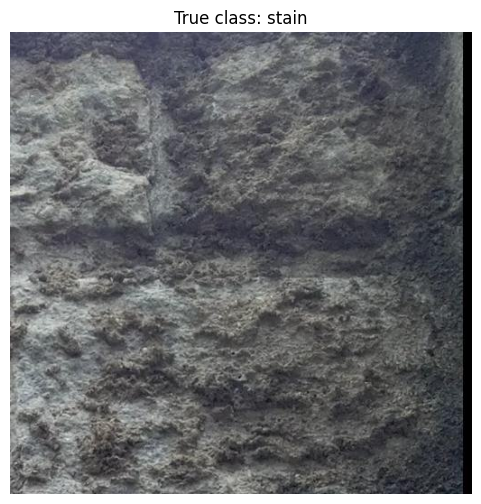

In [47]:
import random
import matplotlib.pyplot as plt
from PIL import Image

# Pick a random test image
test_class = random.choice(test_dataset.classes)
test_folder = os.path.join(split_dir, "test", test_class)

image_name = random.choice(os.listdir(test_folder))
image_path = os.path.join(test_folder, image_name)

print("Class:", test_class)
print("Image:", image_path)

# Display the original image
image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title(f"True class: {test_class}")
plt.show()

True class: stain
Predicted class: algae
Confidence: 96.95%


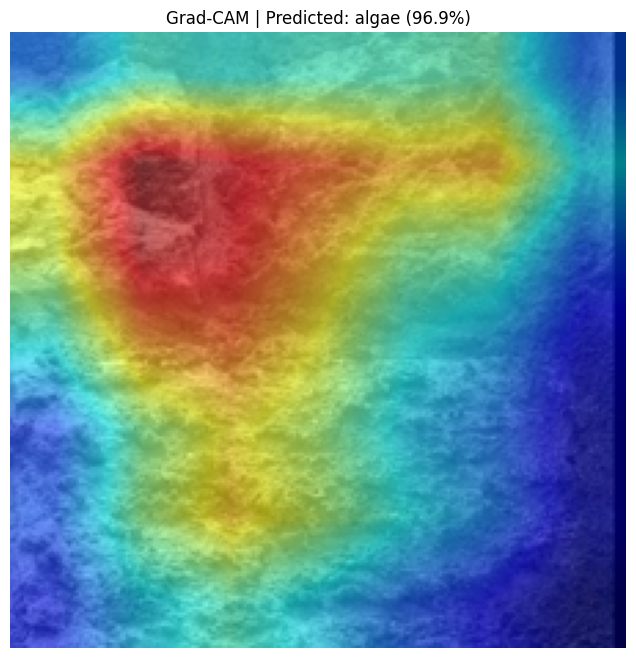

In [48]:
import numpy as np
from PIL import Image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Load image
image = Image.open(image_path).convert("RGB")

# Original image for visualization
rgb_img = np.array(image.resize((224, 224))).astype(np.float32) / 255.0

# Apply the same preprocessing used during validation/testing
input_tensor = val_test_transform(image).unsqueeze(0).to(device)

# Target layer for ResNet18
target_layers = [gradcam_model.layer4[-1]]

# Predict class
with torch.no_grad():
    output = gradcam_model(input_tensor)
    probabilities = torch.softmax(output, dim=1)
    predicted_class = output.argmax(dim=1).item()
    confidence = probabilities[0, predicted_class].item()

# Generate Grad-CAM
cam = GradCAM(
    model=gradcam_model,
    target_layers=target_layers
)

targets = [ClassifierOutputTarget(predicted_class)]

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)[0]

# Overlay heatmap
visualization = show_cam_on_image(
    rgb_img,
    grayscale_cam,
    use_rgb=True
)

print("True class:", test_class)
print("Predicted class:", test_dataset.classes[predicted_class])
print(f"Confidence: {confidence * 100:.2f}%")

plt.figure(figsize=(8, 8))
plt.imshow(visualization)
plt.axis("off")
plt.title(
    f"Grad-CAM | Predicted: {test_dataset.classes[predicted_class]} "
    f"({confidence * 100:.1f}%)"
)
plt.show()

In [49]:
# Show probabilities for every class
probs = probabilities[0].detach().cpu().numpy()

for class_name, prob in zip(test_dataset.classes, probs):
    print(f"{class_name:15s}: {prob * 100:.2f}%")

algae          : 96.95%
major_crack    : 0.03%
minor_crack    : 0.17%
peeling        : 0.01%
plain          : 0.97%
spalling       : 0.03%
stain          : 1.83%


In [51]:
import torch
import torch.nn.functional as F
from PIL import Image

def predict_image(image_path, model, dataset):

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Preprocess
    input_tensor = val_test_transform(image).unsqueeze(0).to(device)

    # Inference
    model.eval()

    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = F.softmax(outputs, dim=1)

    # Top 3 predictions
    top_probs, top_indices = torch.topk(probabilities, 3)

    results = []

    for prob, idx in zip(
        top_probs[0].cpu().numpy(),
        top_indices[0].cpu().numpy()
    ):
        results.append({
            "class": dataset.classes[idx],
            "confidence": float(prob)
        })

    return results

In [52]:
results = predict_image(
    image_path,
    gradcam_model,
    test_dataset
)

for i, result in enumerate(results, 1):
    print(
        f"{i}. {result['class']:15s} "
        f"{result['confidence'] * 100:.2f}%"
    )

1. algae           96.95%
2. stain           1.83%
3. plain           0.97%


In [53]:
severity_map = {
    "plain": "None",
    "algae": "Low",
    "minor_crack": "Low",
    "stain": "Low",
    "peeling": "Medium",
    "spalling": "Medium",
    "major_crack": "High"
}

for result in results:
    result["severity"] = severity_map[result["class"]]

for i, result in enumerate(results, 1):
    print(
        f"{i}. {result['class']:15s} "
        f"{result['confidence'] * 100:.2f}% "
        f"| Severity: {result['severity']}"
    )

1. algae           96.95% | Severity: Low
2. stain           1.83% | Severity: Low
3. plain           0.97% | Severity: None


In [54]:
def inspect_image(image_path, model, dataset):

    results = predict_image(
        image_path,
        model,
        dataset
    )

    top_prediction = results[0]

    inspection = {
        "prediction": top_prediction["class"],
        "confidence": top_prediction["confidence"],
        "severity": severity_map[top_prediction["class"]],
        "top_predictions": results
    }

    return inspection

In [55]:
inspection = inspect_image(
    image_path,
    gradcam_model,
    test_dataset
)

print(inspection)

{'prediction': 'algae', 'confidence': 0.9694585204124451, 'severity': 'Low', 'top_predictions': [{'class': 'algae', 'confidence': 0.9694585204124451}, {'class': 'stain', 'confidence': 0.018346436321735382}, {'class': 'plain', 'confidence': 0.009707685559988022}]}


In [56]:
import random

# Pick 10 random test images
all_test_images = []

for class_name in test_dataset.classes:
    class_dir = os.path.join(split_dir, "test", class_name)

    for filename in os.listdir(class_dir):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            all_test_images.append(
                (os.path.join(class_dir, filename), class_name)
            )

random_samples = random.sample(all_test_images, 10)

for image_path_sample, true_class in random_samples:

    result = inspect_image(
        image_path_sample,
        gradcam_model,
        test_dataset
    )

    predicted = result["prediction"]
    confidence = result["confidence"] * 100

    status = "✓" if predicted == true_class else "✗"

    print(
        f"{status} "
        f"True: {true_class:15s} | "
        f"Pred: {predicted:15s} | "
        f"Confidence: {confidence:6.2f}%"
    )

✓ True: major_crack     | Pred: major_crack     | Confidence:  86.23%
✓ True: minor_crack     | Pred: minor_crack     | Confidence:  99.71%
✓ True: algae           | Pred: algae           | Confidence:  87.60%
✓ True: peeling         | Pred: peeling         | Confidence: 100.00%
✓ True: minor_crack     | Pred: minor_crack     | Confidence:  99.91%
✓ True: major_crack     | Pred: major_crack     | Confidence:  90.53%
✓ True: peeling         | Pred: peeling         | Confidence:  99.37%
✓ True: algae           | Pred: algae           | Confidence: 100.00%
✓ True: major_crack     | Pred: major_crack     | Confidence:  93.35%
✓ True: algae           | Pred: algae           | Confidence: 100.00%


In [57]:
# Find misclassified test images
misclassified = []

for image_path_sample, true_class in all_test_images:

    result = inspect_image(
        image_path_sample,
        gradcam_model,
        test_dataset
    )

    predicted = result["prediction"]

    if predicted != true_class:
        misclassified.append({
            "path": image_path_sample,
            "true": true_class,
            "predicted": predicted,
            "confidence": result["confidence"]
        })

print(f"Total misclassified: {len(misclassified)}")

for item in misclassified[:15]:
    print(
        f"True: {item['true']:15s} | "
        f"Pred: {item['predicted']:15s} | "
        f"Confidence: {item['confidence'] * 100:.2f}%"
    )

Total misclassified: 58
True: algae           | Pred: major_crack     | Confidence: 47.34%
True: algae           | Pred: stain           | Confidence: 41.87%
True: major_crack     | Pred: minor_crack     | Confidence: 98.16%
True: major_crack     | Pred: minor_crack     | Confidence: 96.89%
True: major_crack     | Pred: peeling         | Confidence: 97.24%
True: major_crack     | Pred: minor_crack     | Confidence: 80.21%
True: major_crack     | Pred: minor_crack     | Confidence: 84.59%
True: major_crack     | Pred: peeling         | Confidence: 90.86%
True: major_crack     | Pred: algae           | Confidence: 99.00%
True: major_crack     | Pred: spalling        | Confidence: 89.30%
True: major_crack     | Pred: plain           | Confidence: 50.48%
True: major_crack     | Pred: minor_crack     | Confidence: 96.84%
True: major_crack     | Pred: stain           | Confidence: 52.93%
True: major_crack     | Pred: minor_crack     | Confidence: 90.20%
True: major_crack     | Pred: algae   

In [58]:
# Find the first major_crack -> algae mistake
example = next(
    item for item in misclassified
    if item["true"] == "major_crack"
    and item["predicted"] == "algae"
)

print("Image:", example["path"])
print("True:", example["true"])
print("Predicted:", example["predicted"])
print(f"Confidence: {example['confidence'] * 100:.2f}%")

Image: /kaggle/working/bd3_split/test/major_crack/cls01_154.jpg
True: major_crack
Predicted: algae
Confidence: 99.00%


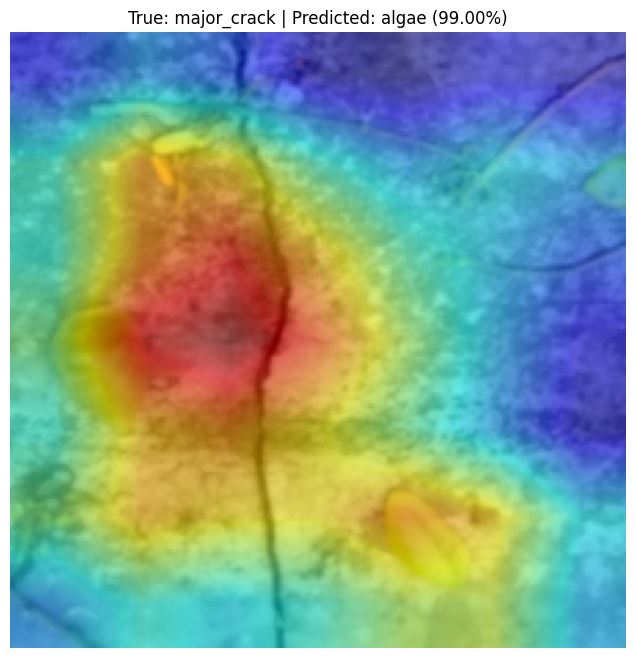

In [60]:
# Use the major_crack -> algae failure case
failure_path = example["path"]

image = Image.open(failure_path).convert("RGB")

# Prepare image
rgb_img = np.array(image.resize((224, 224))).astype(np.float32) / 255.0
input_tensor = val_test_transform(image).unsqueeze(0).to(device)

# Get prediction
with torch.no_grad():
    output = gradcam_model(input_tensor)
    probabilities = torch.softmax(output, dim=1)

predicted_class = output.argmax(dim=1).item()
confidence = probabilities[0, predicted_class].item()

# Grad-CAM
target_layers = [gradcam_model.layer4[-1]]

cam = GradCAM(
    model=gradcam_model,
    target_layers=target_layers
)

targets = [ClassifierOutputTarget(predicted_class)]

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)[0]

visualization = show_cam_on_image(
    rgb_img,
    grayscale_cam,
    use_rgb=True
)

# Show original + Grad-CAM
plt.figure(figsize=(8, 8))
plt.imshow(visualization)
plt.axis("off")
plt.title(
    f"True: major_crack | "
    f"Predicted: {test_dataset.classes[predicted_class]} "
    f"({confidence * 100:.2f}%)"
)
plt.show()

In [61]:
major_to_algae = [
    item for item in misclassified
    if item["true"] == "major_crack"
    and item["predicted"] == "algae"
]

print("Major crack → algae:", len(major_to_algae))

for item in major_to_algae:
    print(
        f"{item['confidence']*100:.2f}% | "
        f"{item['path']}"
    )

Major crack → algae: 3
99.00% | /kaggle/working/bd3_split/test/major_crack/cls01_154.jpg
99.39% | /kaggle/working/bd3_split/test/major_crack/cls01_489.jpg
67.83% | /kaggle/working/bd3_split/test/major_crack/cls01_442.jpg
